In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, Sequential


2026-10-02 09:22:23.125168: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-02 09:22:23.142485: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-02 09:22:23.147774: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    device = "/GPU:0"
    print(f"Using GPU: {gpus[0]}")
else:
    device = "/CPU:0"
    print("No GPU detected. Using CPU.")


Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


I0000 00:00:1790932944.648352    1835 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1790932944.656533    1835 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1790932944.659704    1835 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355


Hyperparameters

In [3]:
IMG_SIZE = 64
CHANNELS = 3 
BATCH_SIZE = 32
LR = 0.001
EPOCHS = 20  # Set to a low number for convenience. Change as needed.

Data location

In [4]:
# make sure the data is downloaded,  extracted and split into train and test - if not please use the 01 notebook.
train_dir = Path("./data/train")
val_dir = Path("./data/test")

Classes

In [5]:
class_names = sorted(
    d.name for d in train_dir.iterdir()
    if d.is_dir()
)

class_to_index = {
    name: i for i, name in enumerate(class_names)
}

num_classes = len(class_names)

print(class_names)
print(class_to_index)

['class_0_non_agri', 'class_1_agri']
{'class_0_non_agri': 0, 'class_1_agri': 1}


At this point we could create a custom data generator to yield batch after batch as follows:

```python
def custom_data_generator(image_paths, labels, batch_size, target_size=(64, 64)):
    """A custom data generator to feed a Keras model."""
    num_samples = len(image_paths)
    while True: 
        # Shuffle data at the beginning of each epoch
        indices = np.arange(num_samples)
        np.random.shuffle(indices)
        shuffled_paths = np.array(image_paths)[indices]
        shuffled_labels = np.array(labels)[indices]
        
        # Generate batch data
        for offset in range(0, num_samples, batch_size):
            batch_paths = shuffled_paths[offset:offset+batch_size]
            batch_labels = shuffled_labels[offset:offset+batch_size]
            
            # Load and preprocess images from the batch
            batch_images = []
            for path in batch_paths:
                img = tf.keras.utils.load_img(path, target_size=target_size)
                img_array = tf.keras.utils.img_to_array(img)
                batch_images.append(img_array)
            
            # Normalize and yield the batch data
            yield np.array(batch_images) / 255.0, np.array(batch_labels)

image_extensions = {".jpg", ".jpeg" }

train_files = [
    (str(f), class_to_index[f.parent.name])
    for f in train_dir.rglob("*")
    if f.is_file() and f.suffix.lower() in image_extensions
]

train_paths = [path for path, label in train_files]
train_labels = [label for path, label in train_files]

gen = custom_data_generator(train_paths, train_labels, 5)
test = next(gen)
print(len(test),test[0].shape, test[1].shape)
```

However we have no special operations to perform and it is more convenient to use the tf.data.Dataset tools.

## Create the datasets from folders of images

Keras offers a handy function to turn folders to datasets directly. Below we have already set up separate validation folder, however Keras can also split a single folder at this stage if that was needed, as follows:

```python
train_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',          # Labels are generated from directory structure
    label_mode='int',           # Labels are encoded as integers (0, 1, ...)
    validation_split=0.2,       # Reserve 20% of images for validation
    subset='training',          # This is the training set
    seed=1337,                  # Shuffle seed for reproducible splits
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',
    label_mode='int',
    validation_split=0.2,
    subset='validation',
    seed=1337,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

```

In [6]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(64, 64),
    batch_size=32,
    label_mode="int",
    shuffle=True,
)

Found 5600 files belonging to 2 classes.


I0000 00:00:1790932944.869853    1835 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1790932944.879800    1835 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1790932944.882319    1835 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1790932945.015327    1835 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

In [7]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(64, 64),
    batch_size=32,
    label_mode="int",
    shuffle=False,
)

Found 400 files belonging to 2 classes.


### Performance set up

The dedicated utility, `tf.data.Dataset`, can be chained with various methods to create a highly performant pipeline. 
- **`.map(function)`:** Applies a given function to every element of the dataset. Here, it is used to apply data augmentation layers. TensorFlow can automatically parallelize this operation.
- **`.cache()`:** Caches the dataset in memory after it's loaded from disk during the first epoch. For subsequent epochs, data will be read from the faster memory cache, significantly speeding up training. This is **only feasible if** the dataset fits in RAM.
- **`.prefetch(buffer_size)`:** It allows the data preprocessing (done on the CPU) to happen in parallel with the model training (done on the GPU). While the GPU is busy with the current batch, the CPU is already preparing the next batch. This overlapping of tasks prevents the GPU from sitting idle and waiting for data, a phenomenon known as an I/O bottleneck.
- **`AUTOTUNE`** lets TensorFlow dynamically decide the optimal buffer size for your computer.

**Important point:** If you cache before the data augmentation, you will not get the changes every epoch as intented! You must first cache and then augment the cached images every time.

In [8]:
train_ds = train_ds.cache()

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
])

# Apply augmentation to the training dataset using map
train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y))

# Configure for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)


In [9]:

my_model = Sequential([
    layers.Input(shape=(IMG_SIZE , IMG_SIZE , CHANNELS)),
    # Conv Block 1: 64x64 -> 32x32
    layers.Conv2D(
        32,
        kernel_size=3,
        strides=1,
        padding="same",
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2),

    # Conv Block 2: 32x32 -> 16x16
    layers.Conv2D(
        64,
        kernel_size=3,
        strides=1,
        padding="same",
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2),

    # Conv Block 3: 16x16 -> 8x8
    layers.Conv2D(
        128,
        kernel_size=3,
        strides=1,
        padding="same",
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2),

    # Conv Block 4: 8x8 -> 4x4
    layers.Conv2D(
        256,
        kernel_size=3,
        strides=1,
        padding="same",
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2),

    # Classifier
    layers.GlobalAveragePooling2D(),
    layers.Dense(
        128,
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.ReLU(),
    layers.Dropout(0.4),
    layers.Dense(num_classes)
])

In [10]:
small_model = Sequential([
    layers.Input(shape=(IMG_SIZE , IMG_SIZE , CHANNELS)),
    # Conv Block 1: 64x64 -> 32x32
    layers.Conv2D(
        16,
        kernel_size=3,
        strides=1,
        padding="same",
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2),

    # Conv Block 2: 32x32 -> 16x16
    layers.Conv2D(
        32,
        kernel_size=3,
        strides=1,
        padding="same",
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2),

    # Conv Block 3: 16x16 -> 8x8
    layers.Conv2D(
        64,
        kernel_size=3,
        strides=1,
        padding="same",
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2),

    # Conv Block 4: 8x8 -> 4x4
    layers.Conv2D(
        128,
        kernel_size=3,
        strides=1,
        padding="same",
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(pool_size=2),

    # Classifier
    layers.GlobalAveragePooling2D(),
    layers.Dense(
        64,
        kernel_initializer=tf.keras.initializers.HeNormal()
    ),
    layers.ReLU(),
    layers.Dropout(0.4),
    layers.Dense(num_classes)
])

In [11]:
loss = "binary_crossentropy"
small_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), 
              metrics=["accuracy"])

print(small_model.summary())

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,786 (417.13 KB)

 Trainable params: 106,306 (415.26 KB)

 Non-trainable params: 480 (1.88 KB)

None


In [12]:
# Create the ModelCheckpoint callback
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(filepath="ai_capstone_keras_best_model.model.keras",
                                monitor='val_loss',      # or 'val_accuracy'
                                mode='min',              # 'min' for loss, 'max' for accuracy
                                save_best_only=True,
                                verbose=1
                               )

In [13]:
print(f"Training on : ==={device}=== with batch size: {BATCH_SIZE} & lr: {LR}")

history = small_model.fit(train_ds, 
                epochs= EPOCHS,
                validation_data=val_ds,
                callbacks=[checkpoint_cb],
                verbose=1
               )

Training on : ===/GPU:0=== with batch size: 32 & lr: 0.001
Epoch 1/20


I0000 00:00:1790932947.919943    1905 service.cc:146] XLA service 0x761a78018d80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790932947.919974    1905 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce GTX 1650, Compute Capability 7.5


 13/175 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8061 - loss: 0.4695

I0000 00:00:1790932951.406753    1905 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9444 - loss: 0.1450
Epoch 1: val_loss improved from inf to 1.19454, saving model to ai_capstone_keras_best_model.model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9446 - loss: 0.1446 - val_accuracy: 0.7725 - val_loss: 1.1945
Epoch 2/20
174/175 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9829 - loss: 0.0536
Epoch 2: val_loss improved from 1.19454 to 0.05740, saving model to ai_capstone_keras_best_model.model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9829 - loss: 0.0535 - val_accuracy: 0.9825 - val_loss: 0.0574
Epoch 3/20
174/175 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9866 - loss: 0.0457
Epoch 3: val_loss improved from 0.05740 to 0.01219, saving model to ai_capstone_keras_best_model.model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9866 - loss: 0.0455 - val_accuracy: 0.9950 - val_loss: 0.0122
Epoch 4/20
172/175 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9852 -

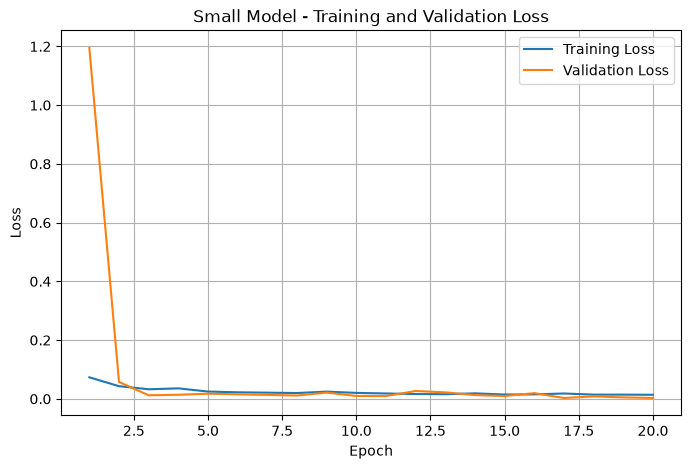

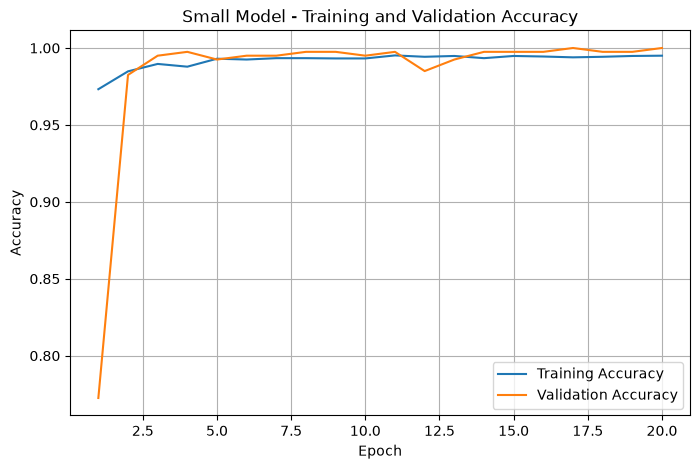

In [14]:
import matplotlib.pyplot as plt

# Extract history
hist = history.history
epochs = range(1, len(hist["loss"]) + 1)

# -------------------------
# Loss
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, hist["loss"], label="Training Loss")
plt.plot(epochs, hist["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Small Model - Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


# -------------------------
# Accuracy
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, hist["accuracy"], label="Training Accuracy")
plt.plot(epochs, hist["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Small Model - Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [15]:
loss = "binary_crossentropy"
my_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), 
              metrics=["accuracy"])


In [16]:
# Create the ModelCheckpoint callback
checkpoint_cb2 = tf.keras.callbacks.ModelCheckpoint(filepath="ai_capstone_keras_my_model.model.keras",
                                monitor='val_loss',      # or 'val_accuracy'
                                mode='min',              # 'min' for loss, 'max' for accuracy
                                save_best_only=True,
                                verbose=1
                               )

In [17]:
history2 = my_model.fit(train_ds, 
                epochs= EPOCHS,
                validation_data=val_ds,
                callbacks=[checkpoint_cb2],
                verbose=1
               )

Epoch 1/20
174/175 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9459 - loss: 0.1592
Epoch 1: val_loss improved from inf to 0.77008, saving model to ai_capstone_keras_my_model.model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9462 - loss: 0.1583 - val_accuracy: 0.8300 - val_loss: 0.7701
Epoch 2/20
171/175 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9861 - loss: 0.0462
Epoch 2: val_loss improved from 0.77008 to 0.03927, saving model to ai_capstone_keras_my_model.model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9861 - loss: 0.0459 - val_accuracy: 0.9875 - val_loss: 0.0393
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9849 - loss: 0.0497
Epoch 3: val_loss did not improve from 0.03927
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9849 - loss: 0.0496 - val_accuracy: 0.9700 - val_loss: 0.0747
Epoch 4/20
174/175 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9860 - loss: 0.0383
Epoch 4: val_loss did not improve from 0.

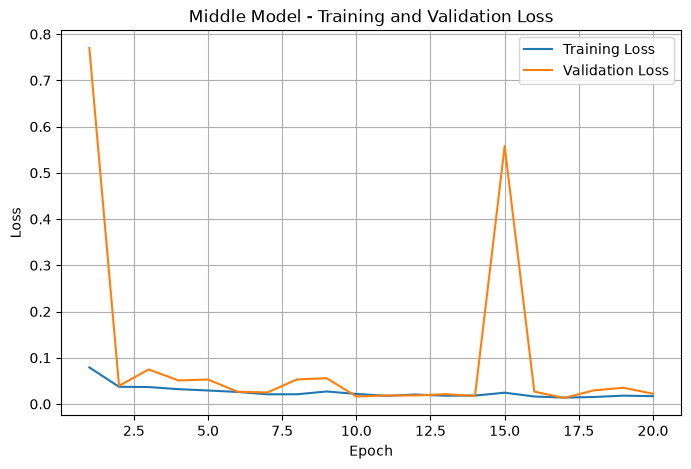

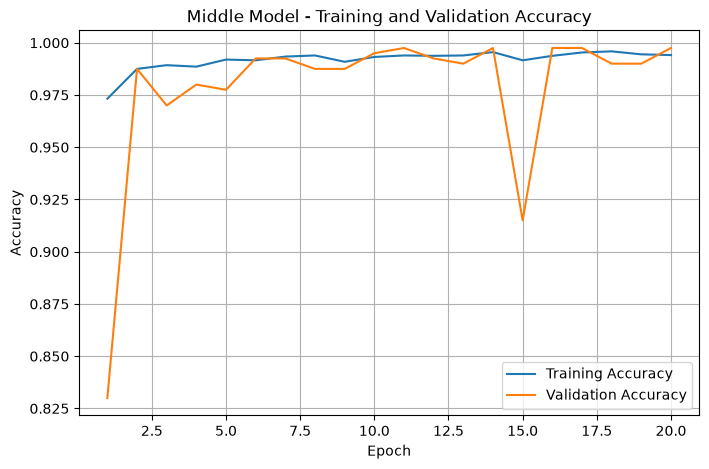

In [19]:
# Extract history
hist = history2.history
epochs = range(1, len(hist["loss"]) + 1)

# -------------------------
# Loss
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, hist["loss"], label="Training Loss")
plt.plot(epochs, hist["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Middle Model - Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


# -------------------------
# Accuracy
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, hist["accuracy"], label="Training Accuracy")
plt.plot(epochs, hist["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Middle Model - Training and Validation Accuracy")
plt.legend()
plt.grid(True)


In [28]:
%%capture
!pip install "onnx<1.18"

In [34]:
small_model.export("small_model_savedmodel")
my_model.export("my_model_savedmodel")

INFO:tensorflow:Assets written to: small_model_savedmodel/assets


INFO:tensorflow:Assets written to: small_model_savedmodel/assets


Saved artifact at 'small_model_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='keras_tensor_25')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  129858589100368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858589104016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858589103248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858589099792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858589103056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858589102672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858589105552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858589102864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858589104208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858589104592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1298585

INFO:tensorflow:Assets written to: my_model_savedmodel/assets


Saved artifact at 'my_model_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='keras_tensor_3')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  129858943816656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858943812048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858943816464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858943816272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858943817232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858943811856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858943820688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858943819344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858943821072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  129858943820304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12985894382

In [35]:
!python -m tf2onnx.convert \
    --saved-model small_model_savedmodel \
    --output small_model.onnx \
    --opset 17

!python -m tf2onnx.convert \
    --saved-model my_model_savedmodel \
    --output my_model.onnx \
    --opset 17

print("Models saved as ONNX.")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 189, in _run_module_as_main
  File "<frozen runpy>", line 112, in _get_module_details
  File "/usr/local/lib/python3.11/dist-packages/tf2onnx/__init__.py", line 12, in <module>
    from . import verbose_logging as logging
  File "/usr/local/lib/python3.11/dist-packages/tf2onnx/verbose_logging.py", line 13, in <module>
    import tensorflow as tf
  File "/usr/local/lib/python3.11/dist-packages/tensorflow/__init__.py", line 47, in <module>
    from tensorflow._api.v2 import __internal__
  File "

In [30]:
import tensorflow as tf
import tf2onnx
import onnx
import ml_dtypes

print("TensorFlow:", tf.__version__)
print("tf2onnx:", tf2onnx.__version__)
print("ONNX:", onnx.__version__)
print("ml_dtypes:", ml_dtypes.__version__)

TensorFlow: 2.17.0
tf2onnx: 1.17.0
ONNX: 1.17.0
ml_dtypes: 0.4.0


In [26]:
import ml_dtypes

print(ml_dtypes.__version__)
print(hasattr(ml_dtypes, "float4_e2m1fn"))

0.4.0
False
